# 01 – Data preparation and the train / validation / test split

Phases 0, 3 and 5: the raw survey file is checked against its recorded checksum, cleaned, labelled and split once into training, validation and test rows.

In [1]:
# Setup: work from the project root so the project code and configs are found
import os, sys, json, platform, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
from src.utils.config import load_config, resolve_path
REPORTS = resolve_path(load_config("project")["paths"]["reports"])
FIG = resolve_path(load_config("project")["paths"]["figures"])
print("Project folder:", ROOT)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)

Project folder: C:\AL_outcome_predictor
Python 3.12.0 | numpy 2.5.4 | pandas 3.0.6


## 1. The raw file is unchanged
The raw files are read-only and their SHA-256 checksums were recorded in Phase 0. This re-computes them now.

In [2]:
from src.data.register_raw import verify
raw_dir = resolve_path(load_config("project")["paths"]["raw"])
manifest = resolve_path("data/raw_checksums.json")
ok = verify(raw_dir, manifest)
print("All raw files match their recorded checksums:", ok)

2026-10-15 16:26:37,198 | INFO     | src.data.register_raw | All 5 raw files match their recorded checksums


All raw files match their recorded checksums: True


## 2. Cleaning log (Phase 3)
Every change made by the cleaning script is logged. Only the step, the column and the number of rows are shown here.

In [3]:
log = pd.read_csv(REPORTS / "phase03" / "cleaning_log.csv")
log[["step", "column", "rows_affected"]]

,step,column,rows_affected
0,strip_whitespace,al_combined_maths,1
1,value_correction,al_district,1
2,check_duplicates,all,0
3,skipped_question,school_activities,268
4,skipped_question,leadership_roles,256
5,skipped_question,ol_tuition_subjects,260
6,check_zscore_extremes,zscore,0
7,flag_rare_combination,degree_program,1
8,exclude_from_modelling,row,1
9,drop_column,timestamp,0


## 3. Rows used for modelling and the class counts of each target

In [4]:
from src.data.split import modelling_rows
rows = modelling_rows()
print("Modelling rows:", len(rows), "| columns:", rows.shape[1])
counts = pd.read_csv(REPORTS / "phase03" / "class_counts.csv")
counts

Modelling rows: 1014 | columns: 82


,target,class,count,share
0,university_group,Western,336,0.331
1,university_group,Northern and Eastern,286,0.282
2,university_group,Central and Highlands,217,0.214
3,university_group,Southern,90,0.089
4,university_group,North Central and North Western,86,0.085
5,degree_category,Biological Science,233,0.230
6,degree_category,"Computing, IT, AI or Data Science",177,0.174
7,degree_category,Agriculture or Food Science,158,0.156
8,degree_category,Allied Health Sciences,156,0.154
9,degree_category,Physical Science,138,0.136


## 4. The split (Phase 4/5)
The split was made once with the project seed, stratified, and locked with a checksum. `verify_split` checks the split file against that lock.

In [5]:
from src.data.split import verify_split
split = pd.read_csv(resolve_path(load_config("split")["files"]["split"]))
verify_split(split)
print("Split file matches its lock record.")
print(split["split"].value_counts().rename("rows").to_frame())
pd.read_csv(REPORTS / "phase05" / "zscore_by_split.csv").set_index("split")

Split file matches its lock record.
            rows
split           
train        709
test         153
validation   152


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,709.0,1.548,0.422,0.754,1.218,1.529,1.856,2.611
validation,152.0,1.530,0.423,0.753,1.197,1.493,1.835,2.414
test,153.0,1.535,0.435,0.777,1.173,1.514,1.887,2.385


## 5. The test set is locked
Until Phase 7 the code refused to read the test rows without an unlock word. This shows the lock still works (the test rows are not read here).

In [6]:
from src.data.split import load_split_rows
try:
    load_split_rows("test")
except Exception as error:
    print(type(error).__name__, "->", error)

TestSetLockedError -> The test set is locked until Phase 7.


## 6. Z-score band edges, learned from the training rows only

{'edges': [1.3314, 1.7423], 'fitted_on': 'train', 'rows': 709}


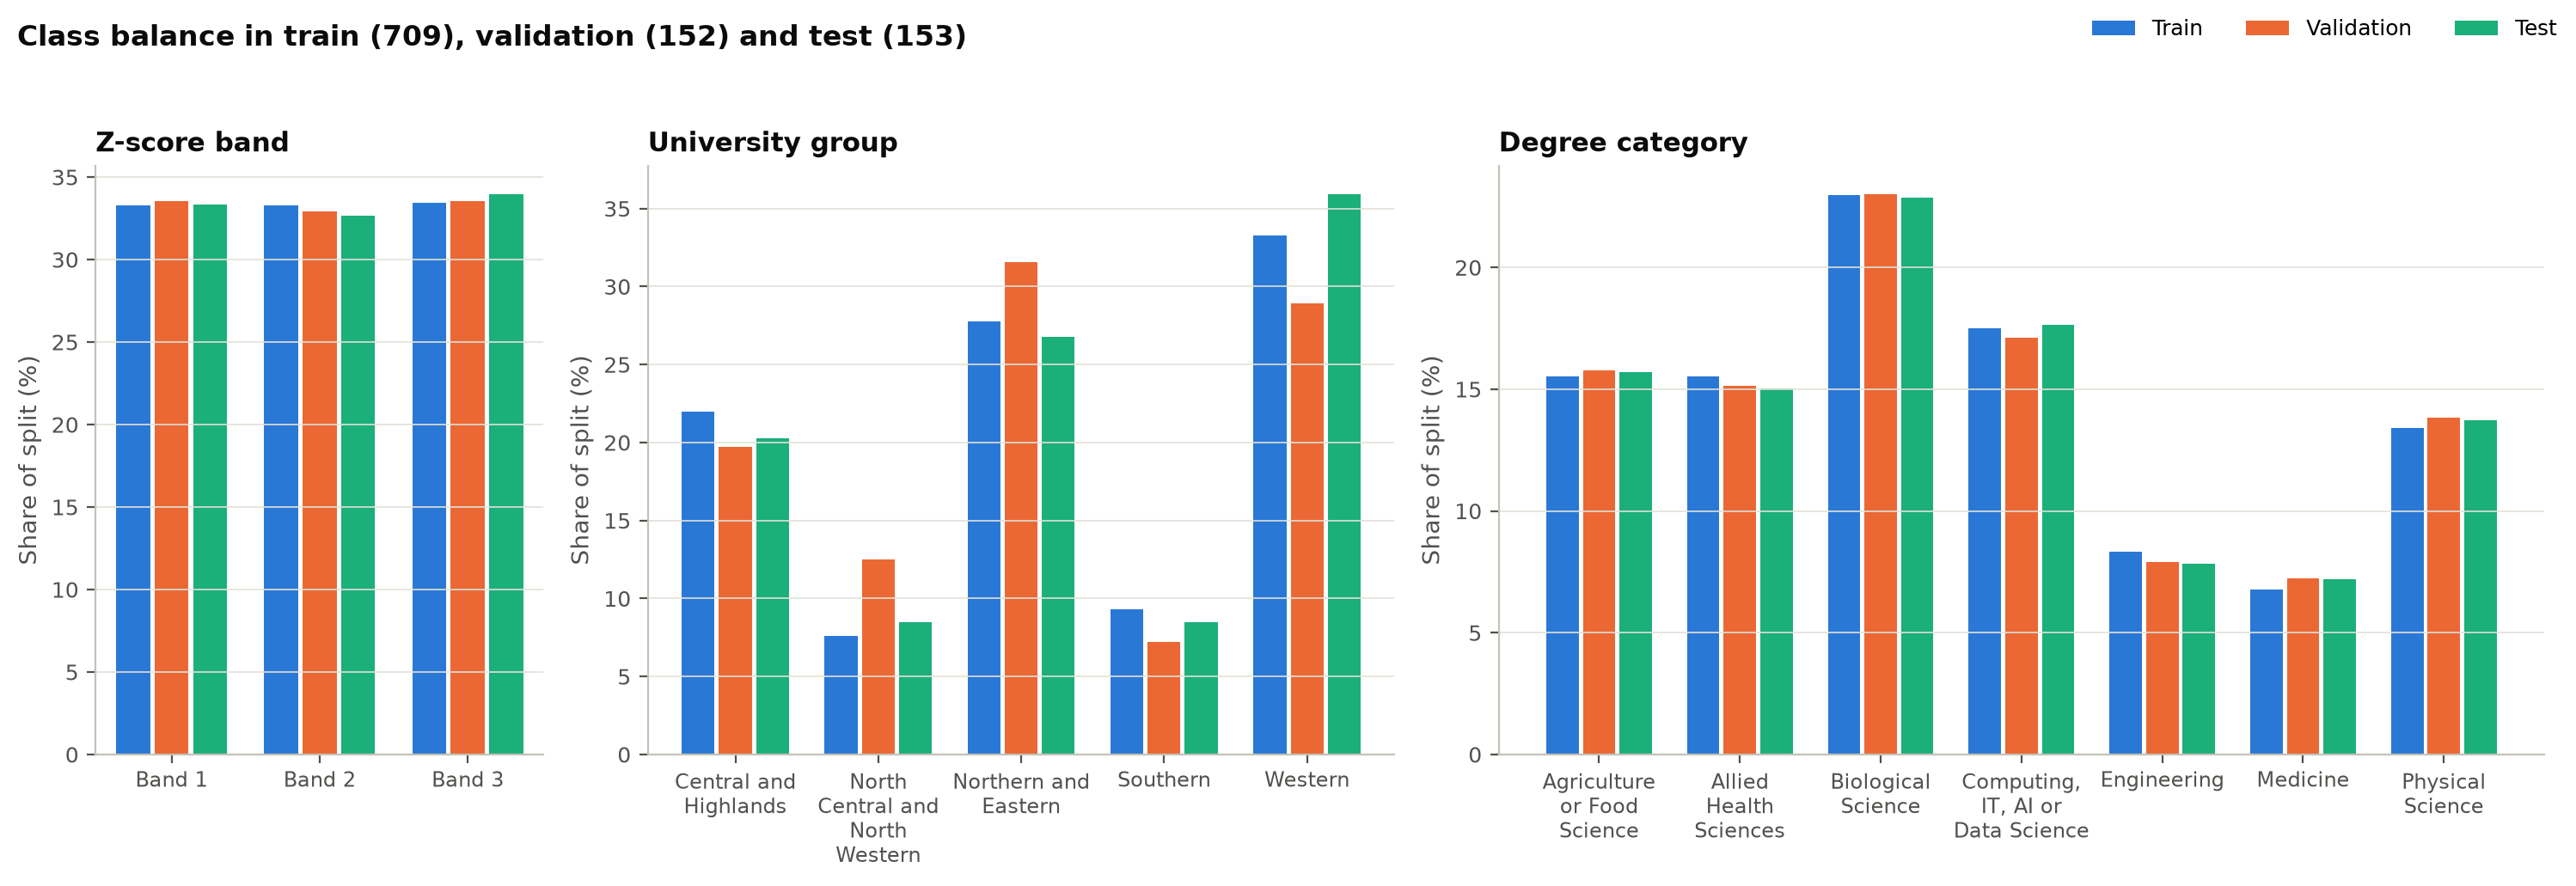

In [7]:
print(json.loads(resolve_path("data/processed/zscore_band_edges.json").read_text("utf-8")))
display(Image(str(FIG / "phase05_class_balance.png"), width=760))